In [1]:
!mamba install pandas


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.858 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [ ]:
!mamba install pandas seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.414 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("ride_hailing_dataset.csv")
display(df.head())

,trip_id,city,service_type,fare,distance_km,payment_method,trip_rating,gender
0,T001,Lahore,Uber,984.44,17.2,Cash,3,Female
1,T002,Islamabad,Uber,539.46,2.5,Wallet,5,Female
2,T003,Karachi,Careem,401.60,8.0,Card,4,Male
3,T004,Lahore,Uber,932.56,16.2,Wallet,3,Female
4,T005,Lahore,Rickshaw,148.61,19.2,Card,5,Female


#Q1: What is the average fare by service type?

In [3]:
avg_fare_service = df.groupby("service_type")["fare"].mean()
display(avg_fare_service)

service_type
Careem      544.975000
InDrive     573.514783
Rickshaw    486.637200
Uber        486.125455
Name: fare, dtype: float64

#Q2: Which city has the most trips?

In [4]:
most_trips_city = df["city"].mode()[0]
print(f"The city with the most trips is: {most_trips_city}")
print(df["city"].value_counts())

The city with the most trips is: Islamabad
city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64


#Q3: What is the average distance per trip?

In [5]:
avg_distance = df["distance_km"].mean()
print(f"The average distance per trip is: {avg_distance:.2f} km")

The average distance per trip is: 9.61 km


#Q4: Compare trip ratings by gender.

In [6]:
rating_by_gender = df.groupby("gender")["trip_rating"].mean()
display(rating_by_gender)

# Optional: full summary stats (count, mean, std, min, quartiles, max)
display(df.groupby("gender")["trip_rating"].describe())

gender
Female    2.823529
Male      3.326531
Name: trip_rating, dtype: float64

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,51.0,2.823529,1.465686,1.0,1.0,3.0,4.0,5.0
Male,49.0,3.326531,1.463269,1.0,2.0,4.0,5.0,5.0


#Q5: Make a bar chart of service type vs. average fare.

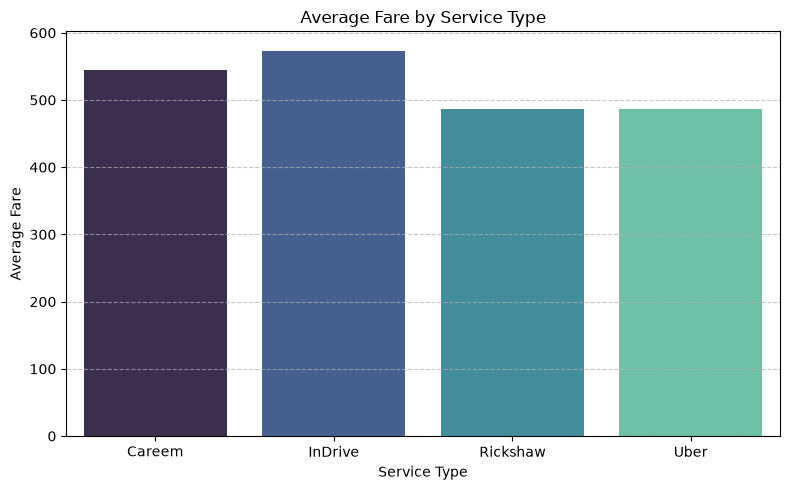

In [7]:
avg_fare_df = df.groupby("service_type")["fare"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=avg_fare_df, x="service_type", y="fare", hue="service_type", palette="mako"
)
plt.title("Average Fare by Service Type")
plt.xlabel("Service Type")
plt.ylabel("Average Fare")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()